<a href="https://colab.research.google.com/github/MohammedKaif-19/Data-Analytics-Assignment/blob/main/Titanic_Survival_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Libraries imported successfully!
Upload your Titanic train.csv file


Saving train.csv to train (2).csv

Dataset uploaded successfully!

FIRST FIVE ROWS


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



DATASET SHAPE
(891, 12)

COLUMN INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

MISSING VALUES
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare   

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Data preprocessing completed!


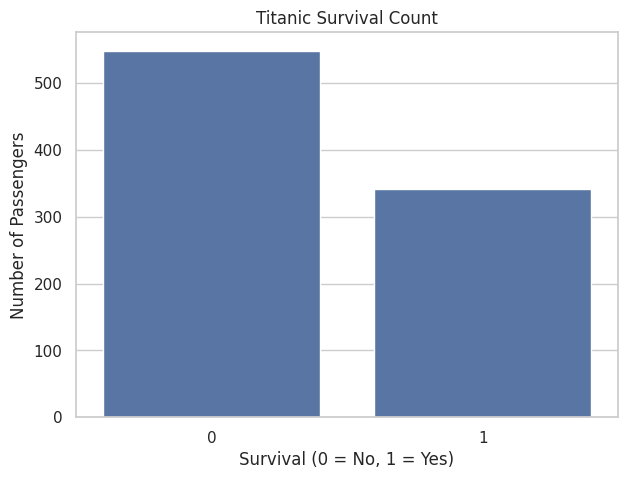

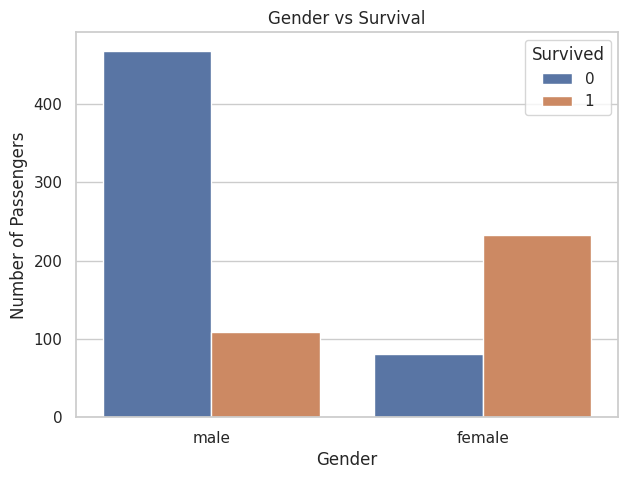

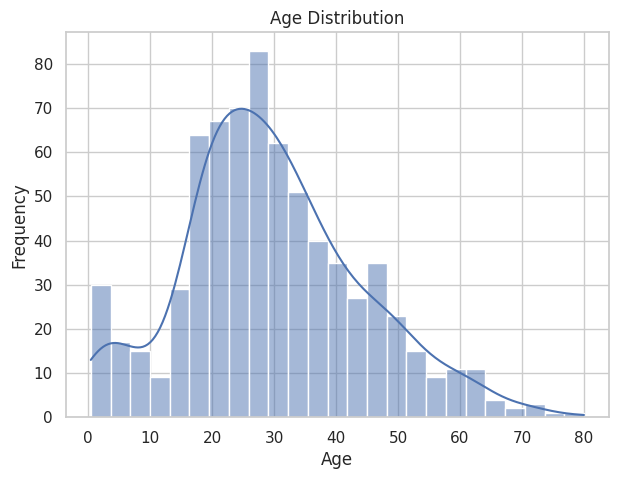

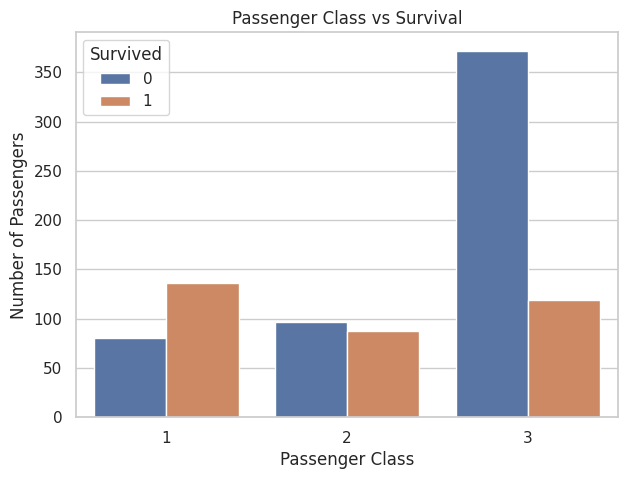

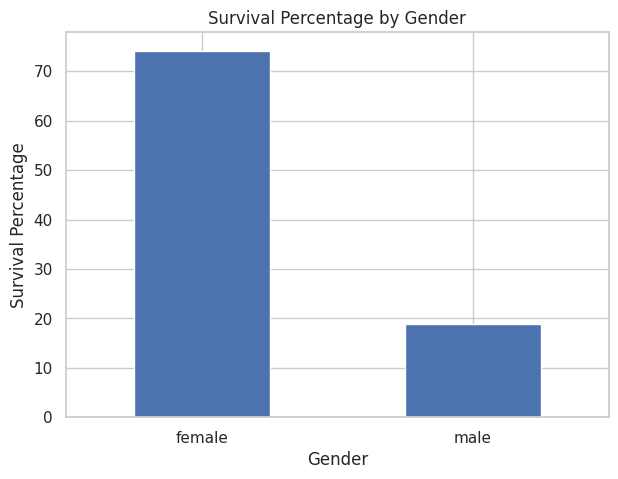

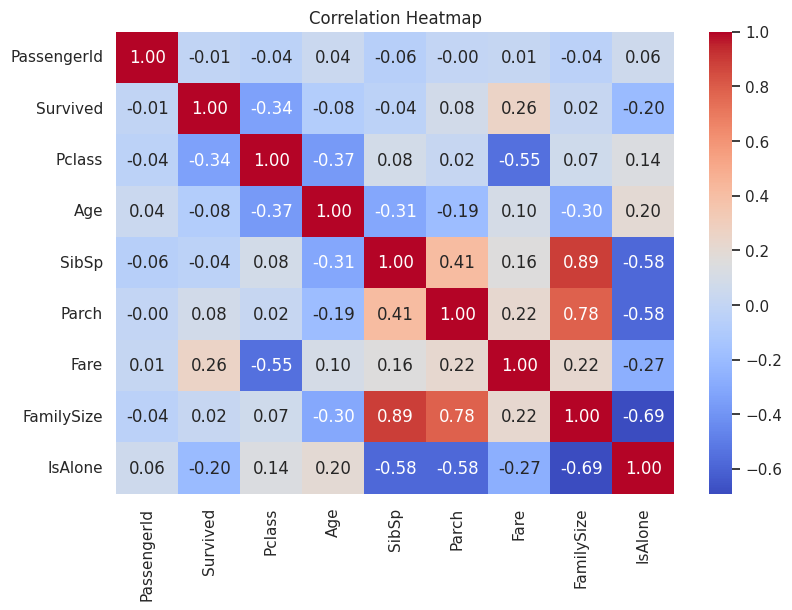

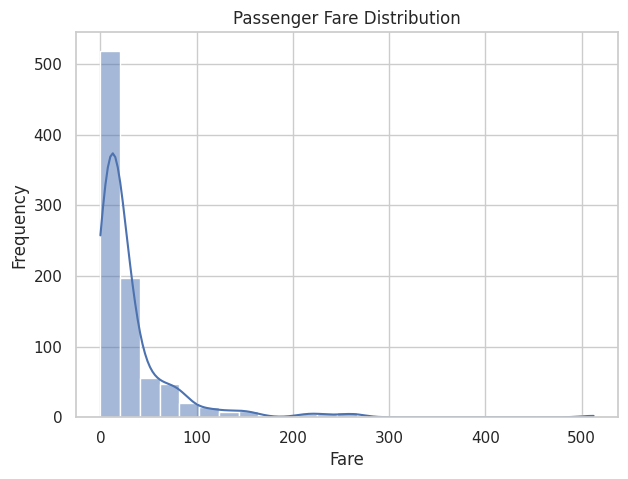

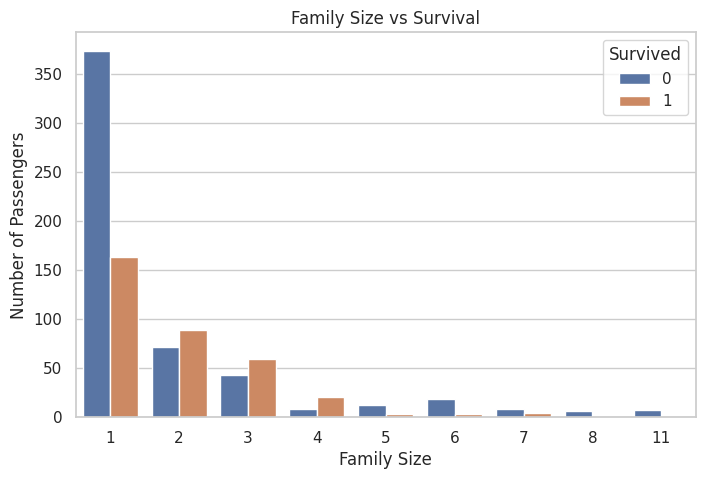


All visualizations generated successfully!

Input features: (891, 10)
Output target: (891,)

Training records: 712
Testing records: 179

Training Random Forest Model...
Model trained successfully!

Actual values:
[0 0 1 0 1 1 1 0 0 0 0 0 1 0 0]

Predicted values:
[0 0 0 0 1 0 1 0 0 0 0 0 1 0 0]

========== MODEL PERFORMANCE ==========
Accuracy : 81.56 %
Precision: 81.03 %
Recall   : 68.12 %
F1 Score : 74.02 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

Not Survived       0.82      0.90      0.86       110
    Survived       0.81      0.68      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.82      0.82      0.81       179



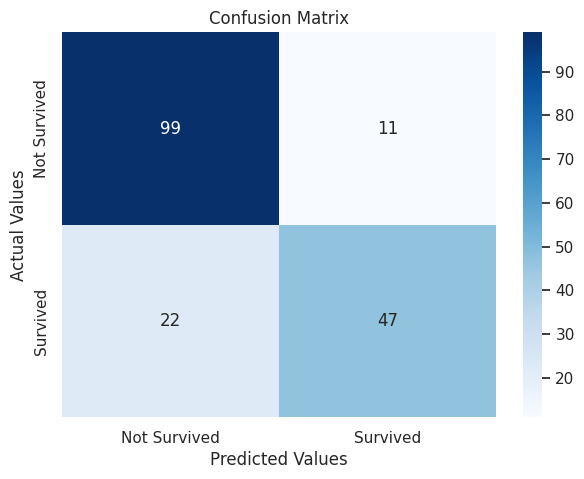

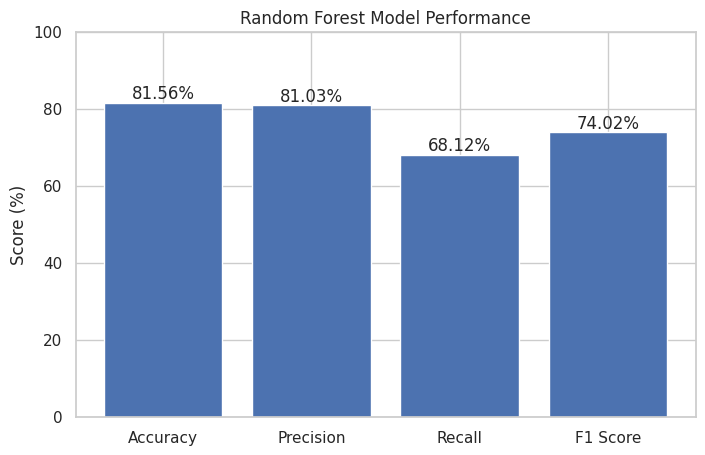

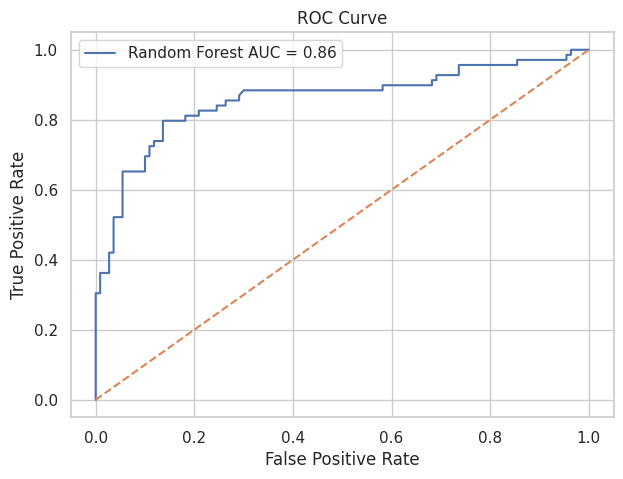

ROC-AUC Score: 0.859


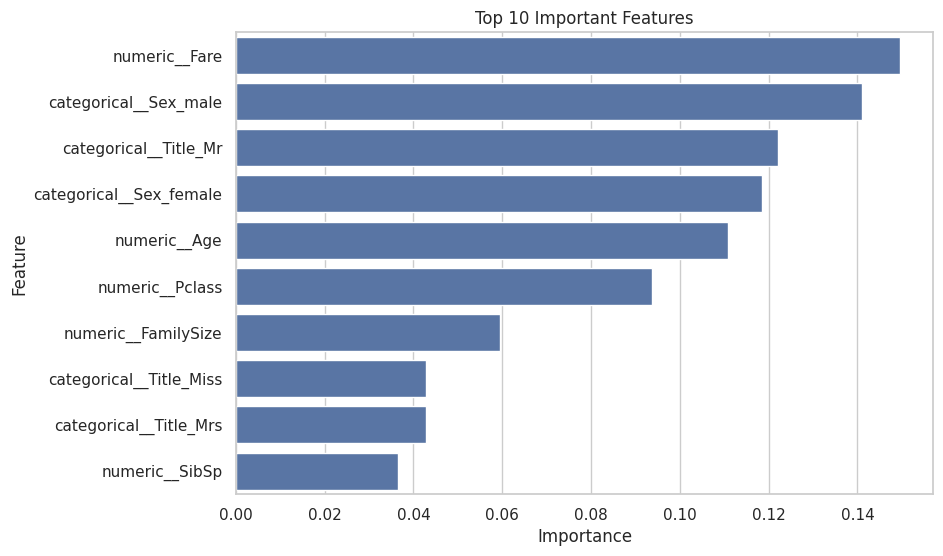


           PROJECT CONCLUSION

The Titanic Survival Prediction project was developed
using the Random Forest Machine Learning algorithm.

The dataset was collected from Kaggle.

Data cleaning and preprocessing were performed
to handle missing values.

Exploratory Data Analysis was performed using
different graphs and visualizations.

The dataset was divided into 80% training data
and 20% testing data.

The Random Forest model was trained to predict
whether passengers survived or not.

Model performance was evaluated using Accuracy,
Precision, Recall, F1 Score and ROC-AUC.

This project demonstrates how machine learning
can be used to analyze data and make predictions.

Final Accuracy: 81.56 %
Final ROC-AUC: 0.859

PROJECT COMPLETED SUCCESSFULLY!


In [6]:
# ==========================================================
# TITANIC SURVIVAL PREDICTION USING RANDOM FOREST
# DATA ANALYTICS PROJECT
# ==========================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

print("Libraries imported successfully!")


# 2. UPLOAD DATASET

print("Upload your Titanic train.csv file")

uploaded = files.upload()

filename = next(
    (f for f in uploaded if f.lower().endswith('.csv')),
    None
)

if filename is None:
    raise ValueError("Please upload train.csv")

df = pd.read_csv(filename)

print("\nDataset uploaded successfully!")


# 3. UNDERSTAND DATASET

print("\nFIRST FIVE ROWS")
display(df.head())

print("\nDATASET SHAPE")
print(df.shape)

print("\nCOLUMN INFORMATION")
print(df.info())

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nSTATISTICAL SUMMARY")
display(df.describe())


# 4. DATA PREPROCESSING

data = df.copy()

# Extract title from passenger name
data['Title'] = data['Name'].str.extract(
    r',\s*([^.]*)\.',
    expand=False
)

# Combine rare titles
data['Title'] = data['Title'].replace(
    ['Lady', 'Countess', 'Capt', 'Col', 'Don',
     'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer',
     'Dona'],
    'Rare'
)

data['Title'] = data['Title'].replace({
    'Mlle': 'Miss',
    'Ms': 'Miss',
    'Mme': 'Mrs'
})

# Create family size
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1

# Identify passengers travelling alone
data['IsAlone'] = (data['FamilySize'] == 1).astype(int)

print("\nData preprocessing completed!")


# ==========================================================
# 5. DATA VISUALIZATION
# ==========================================================

# GRAPH 1: SURVIVAL COUNT

plt.figure(figsize=(7,5))
sns.countplot(data=data, x='Survived')
plt.title("Titanic Survival Count")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()


# GRAPH 2: GENDER VS SURVIVAL

plt.figure(figsize=(7,5))
sns.countplot(data=data, x='Sex', hue='Survived')
plt.title("Gender vs Survival")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.show()


# GRAPH 3: AGE DISTRIBUTION

plt.figure(figsize=(7,5))
sns.histplot(data=data, x='Age', bins=25, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


# GRAPH 4: PASSENGER CLASS VS SURVIVAL

plt.figure(figsize=(7,5))
sns.countplot(data=data, x='Pclass', hue='Survived')
plt.title("Passenger Class vs Survival")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.show()


# GRAPH 5: SURVIVAL PERCENTAGE BY GENDER

gender = data.groupby('Sex')['Survived'].mean() * 100

plt.figure(figsize=(7,5))
gender.plot(kind='bar')
plt.title("Survival Percentage by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Percentage")
plt.xticks(rotation=0)
plt.show()


# GRAPH 6: CORRELATION HEATMAP

plt.figure(figsize=(9,6))

sns.heatmap(
    data.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()


# GRAPH 7: FARE DISTRIBUTION

plt.figure(figsize=(7,5))
sns.histplot(data=data, x='Fare', bins=25, kde=True)
plt.title("Passenger Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.show()


# GRAPH 8: FAMILY SIZE VS SURVIVAL

plt.figure(figsize=(8,5))
sns.countplot(data=data, x='FamilySize', hue='Survived')
plt.title("Family Size vs Survival")
plt.xlabel("Family Size")
plt.ylabel("Number of Passengers")
plt.show()


print("\nAll visualizations generated successfully!")


# ==========================================================
# 6. SELECT INPUT AND OUTPUT
# ==========================================================

features = [
    'Pclass',
    'Sex',
    'Age',
    'SibSp',
    'Parch',
    'Fare',
    'Embarked',
    'Title',
    'FamilySize',
    'IsAlone'
]

X = data[features]
y = data['Survived']

print("\nInput features:", X.shape)
print("Output target:", y.shape)


# ==========================================================
# 7. SPLIT DATASET
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


# ==========================================================
# 8. HANDLE MISSING VALUES AND ENCODE DATA
# ==========================================================

numeric_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X.select_dtypes(
    include='object'
).columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_columns),
    ('categorical', categorical_pipeline, categorical_columns)
])


# ==========================================================
# 9. RANDOM FOREST MODEL
# ==========================================================

model = Pipeline([
    ('preprocessing', preprocessor),
    ('random_forest', RandomForestClassifier(
        n_estimators=100,
        max_depth=7,
        random_state=42,
        n_jobs=-1
    ))
])

print("\nTraining Random Forest Model...")

model.fit(X_train, y_train)

print("Model trained successfully!")


# ==========================================================
# 10. PREDICTIONS
# ==========================================================

y_pred = model.predict(X_test)

print("\nActual values:")
print(y_test.values[:15])

print("\nPredicted values:")
print(y_pred[:15])


# ==========================================================
# 11. MODEL EVALUATION
# ==========================================================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("\n========== MODEL PERFORMANCE ==========")

print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")


# ==========================================================
# 12. CLASSIFICATION REPORT
# ==========================================================

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Not Survived', 'Survived']
))


# ==========================================================
# 13. CONFUSION MATRIX
# ==========================================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()


# ==========================================================
# 14. PERFORMANCE COMPARISON GRAPH
# ==========================================================

scores = {
    'Accuracy': accuracy * 100,
    'Precision': precision * 100,
    'Recall': recall * 100,
    'F1 Score': f1 * 100
}

plt.figure(figsize=(8,5))

bars = plt.bar(scores.keys(), scores.values())

plt.title("Random Forest Model Performance")
plt.ylabel("Score (%)")
plt.ylim(0, 100)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha='center'
    )

plt.show()


# ==========================================================
# 15. ROC CURVE
# ==========================================================

probability = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, probability)

auc = roc_auc_score(y_test, probability)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest AUC = {auc:.2f}"
)

plt.plot([0,1], [0,1], linestyle='--')

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

print("ROC-AUC Score:", round(auc, 3))


# ==========================================================
# 16. FEATURE IMPORTANCE
# ==========================================================

feature_names = model.named_steps[
    'preprocessing'
].get_feature_names_out()

importance = model.named_steps[
    'random_forest'
].feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(9,6))

sns.barplot(
    data=importance_df.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()


# ==========================================================
# 17. FINAL CONCLUSION
# ==========================================================

print("\n========================================")
print("           PROJECT CONCLUSION")
print("========================================")

print("""
The Titanic Survival Prediction project was developed
using the Random Forest Machine Learning algorithm.

The dataset was collected from Kaggle.

Data cleaning and preprocessing were performed
to handle missing values.

Exploratory Data Analysis was performed using
different graphs and visualizations.

The dataset was divided into 80% training data
and 20% testing data.

The Random Forest model was trained to predict
whether passengers survived or not.

Model performance was evaluated using Accuracy,
Precision, Recall, F1 Score and ROC-AUC.

This project demonstrates how machine learning
can be used to analyze data and make predictions.
""")

print("Final Accuracy:", round(accuracy * 100, 2), "%")
print("Final ROC-AUC:", round(auc, 3))

print("\nPROJECT COMPLETED SUCCESSFULLY!")